# EX10 -  Reasons of Overall Model Test (OMT) rejection

In this Python exercise, we will investigate a curve fitting problem using a synthetic sea-level-rise dataset.

The objective is to explore possible reasons for an OMT rejection, including:



*   an outlier in the observations;
*   an incorrectly specified functional model;
*   an underestimated overall scale of the observation uncertainties.

*Important*: The OMT assesses the compatibility of the observations with the adopted mathematical model, under the assumption that they are affected only by the random errors described by the stochastic model. An OMT rejection does not identify its cause by itself.

The dataset is provided in the [`W6_syntheticdata4.txt`](https://github.com/RobertaRavanelli/2026_2027_Observation_Theory/blob/main/sample_data/W6_syntheticdata4.txt) file available on github. It contains yearly sea level measurements (in cm) collected over 20 years.

The observations epochs, expressed in years, are `t = [1, 2, 3, ..., 20]`.

Assume that the observations are independent and normally distributed, with a standard deviation of σ = 2 cm.

The sea level at time zero ($t_0$ = 0), denoted by $x_0$, is unknown and must be estimated together with the other model parameters.

A-priori information:

* there may be at most one outlier in the dataset;

* the correct functional model is uncertain: both a linear trend and a quadratic model (representing an accelerating rise) are plausible;

* the assumed standard deviation, σ = 2 cm, may be too optimistic (i.e., the observation uncertainties may be underestimated)..
  

**Part 1 – Initial adjustment using the linear model**

1. Import the dataset and define the observation vector $y$ and the corresponding observation epochs $t$.
2. Define the covariance matrix of the observations $Q_{yy}$, according to the assumed stochastic model.
3. Define the design matrix $A$ (functional model), for the linear trend model $E\{\underline{y}\} = x_0 + x_1 \cdot t$.
4. Apply BLUE to estimate the model parameters: $\hat{x}={(A^T{Q_{yy}^{-1}}A)}^{-1}A^T{Q_{yy}^{-1}}y$.
5. Compute the adjusted observations: $\hat{y}= A\hat{x}$.
6. Compute the residuals: $\hat{e}= y - \hat{y}$.
7. Compute the weighted sum of the squared residuals which will serve as the OMT test statistic $T$:  $T=\hat{e}^T{Q_{yy}^{-1}}\hat{e}$.
8. Compute the covariance matrix of the estimates $\hat{x}$: $Q_{\hat{x}\hat{x}}={(A^T{Q_{yy}^{-1}}A)}^{-1}$.
9. Compute the covariance matrix of the adjusted onservations $\hat{y}$: $Q_{\hat{y}\hat{y}}= A Q_{\hat{x}\hat{x}} A^T$.
10. Compute the pointwise confidence intervals at 95% probability of the adjusted observations $\hat{y}$, using the using the diagonal elements of the covariance matrix of the adjusted obervations $Q_{\hat{y}\hat{y}}$:
      * $ {\hat{y}_{i}}_{L} =  \hat{y}_{i} - scaling\_factor(conf\_level) \cdot {\sigma}_{\hat{y}_{i}} $;
      * $ {\hat{y}_{i}}_{U} =  \hat{y}_{i} + scaling\_factor(conf\_level) \cdot {\sigma}_{\hat{y}_{i}} $.
11. Compute the covariance matrix of the residuals $\hat{e}$: $Q_{\hat{e}\hat{e}}= Q_{yy} - Q_{\hat{y}\hat{y}}$.
12. Test the linear trend solution using the OMT at the 5% significance level:
  * choose a significance level ($\alpha$) equal to 5% and compute the critical value $K$ from the chi-square distribution with m − n degrees of freedom, where $m$ is the number of observations and $n$ is the number of estimated parameters
  * apply the OMT decision rule:
      * if $T \leq K →$ test passed;
      * if $T > K →$ test rejected;

**Part 2 – Investigating the presence of an outlier**

13. If the OMT is rejected ($T > K$) for the linear trend model,  investigate whether an outlier could be responsible for the rejection. We can consider the observation with the largest absolute normalized residual as a potential outlier.
To identify a potential outlier:

      * Compute the normalized residuals:
        rᵢ = êᵢ / √Q_(êê,ii)
        where êᵢ is the i-th residual and Q_(êê,ii) is the corresponding diagonal element of the residual covariance matrix $Q_{êê}$, i.e. the variance of the i-th residual ($\sigma^2_{\hat{e}_i}$).

      * Identify the observation with the largest absolute normalized residual, |rᵢ|, and consider it as a potential outlier.

14. Remove the candidate outlier and repeat the linear-model adjustment using the remaining observations. Recompute the adjusted observations, residuals, covariance matrices and pointwise 95% confidence intervals.
15. Apply the OMT to the new solution (linear trend model without the candidate outlier), using the updated number of observations and the corresponding degrees of freedom.

**Part 3 – Investigating the functional model**

16. If the OMT is still rejected, investigate whether the linear functional model is incorrectly specified. Import the original dataset, including all observations, and define a new design matrix A for the quadratic trend model:
 $E\{\underline{y}\} = x_0 + x_1 \cdot t + x_2 \cdot t^2$.
17. Apply BLUE again and compute the adjusted observations, residuals, covariance matrices and pointwise 95% confidence intervals.
18. Apply the OMT to the quadratic model using the 5% significance level;
19. If the OMT is rejected, investigate the possibility of an outlier under the quadratic model. Identify the observation the largest absolute normalized residual and consider it as a potential outlier.
20. Remove the candidate outlier and repeat the quadratic-model adjustment. Recompute the adjusted observations, residuals, covariance matrices and pointwise 95% confidence intervals.
21. Apply the OMT to the new solution (quadratic model without the candidate outlier), using the updated number of observations and the corresponding degrees of freedom.

**Part 4 – Investigating the overall scale of the stochastic model**

22. If the OMT is still rejected, investigate whether the stochastic model is incorrectly specified because the overall scale of the observation uncertainties is underestimated. Assuming that the covariance structure is correctly specified and that the discrepancy concerns only its overall scale, estimate the variance scaling factor s:
 $s=\frac{\hat{\underline{e}}^T Q_{yy}^-1\hat{\underline{e}}}{m-n}=\frac{T}{m-n}$

  Use the factor s to rescale the covariance matrix:
  $Q_{yy,new}=\frac{T}{m-n}Q_{yy} $.
  
  Note that s is dimensionless and represents the ratio between the estimated and the initially assumed variance factors.

23. apply BLUE to the quadratic-model adjustment without the candidate outlier, using the new covariance matrix of the observations $Q_{yy,new}$. Recompute the adjusted observations, residuals, covariance matrices and pointwise 95% confidence intervals.

24. test the new solution (quadratic model without the outlier and with a new stochastic model) with OMT at the 5% significance level.

By following this iterative procedure, you will identify why the OMT is rejected:

*   incorrect functional model: the adopted mathematical relationship between the observations and the unknown parameters is inadequate;
*   presence of an outlier: one observation may contain an error that cannot be explained by the assumed random-error model;
*   incorrect stochastic model: the observation uncertainties may be underestimated, or the assumed covariance structure may be incorrect;
*   combination of these causes: more than one source of model error may be present simultaneously.

***Q1:*** Implement the 24 steps described in the code cells below, covering the entire workflow from data import and model adjustment to OMT testing and, where appropriate, outlier removal and stochastic-model rescaling.

Then, answer the questions that follow.

A summary of the OMT formulas is provided in the lecture slides and reproduced below for convenience.

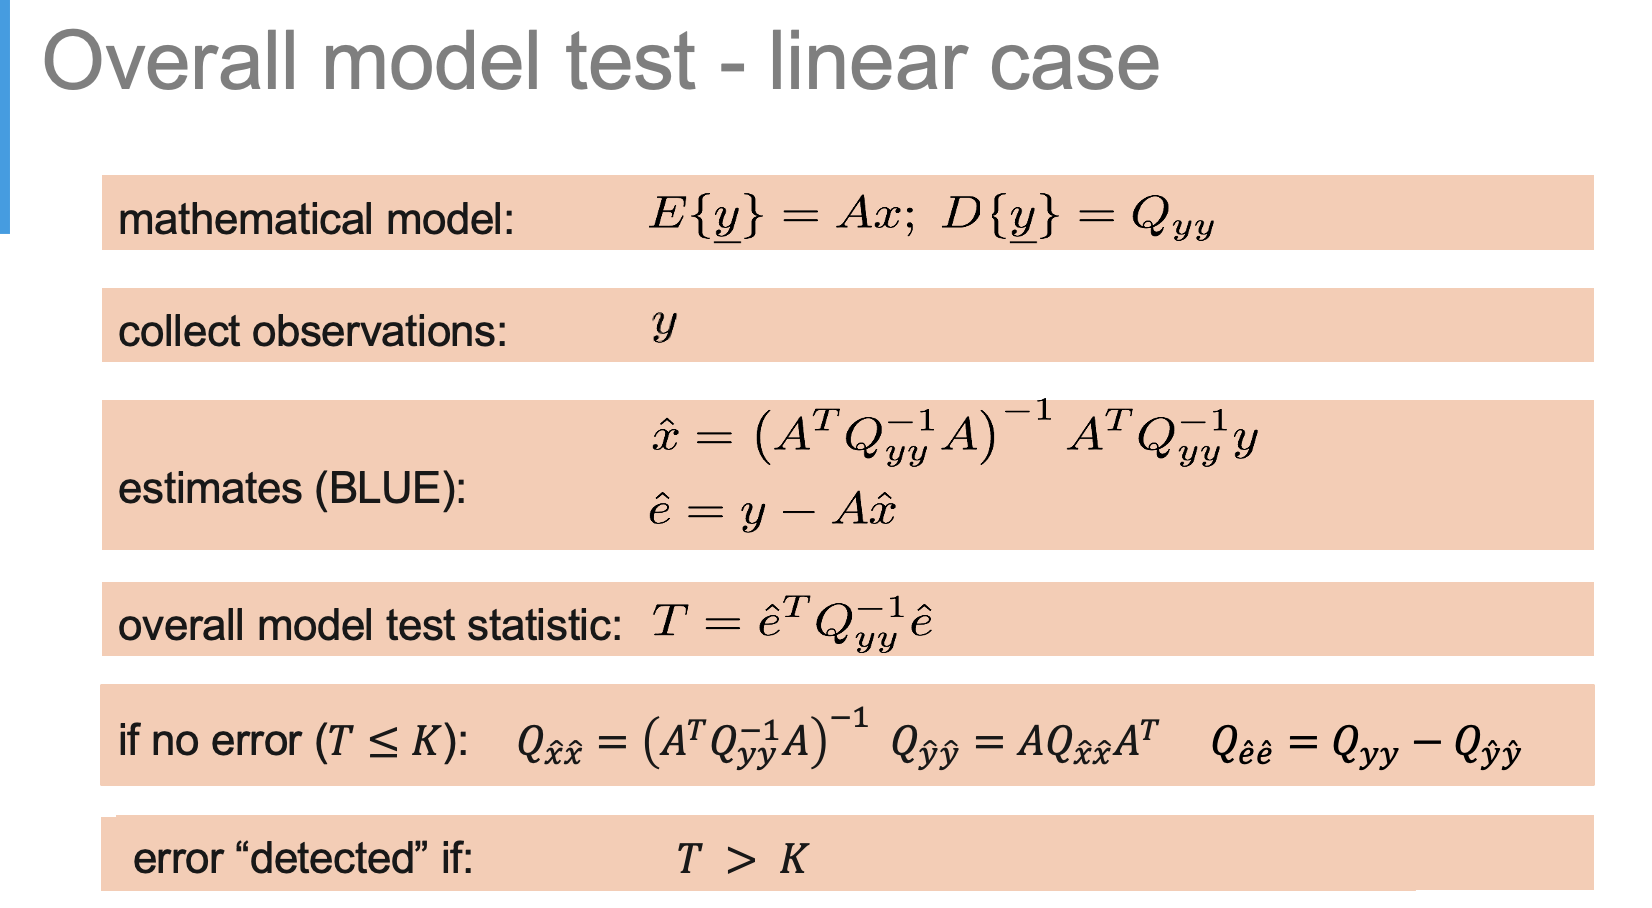


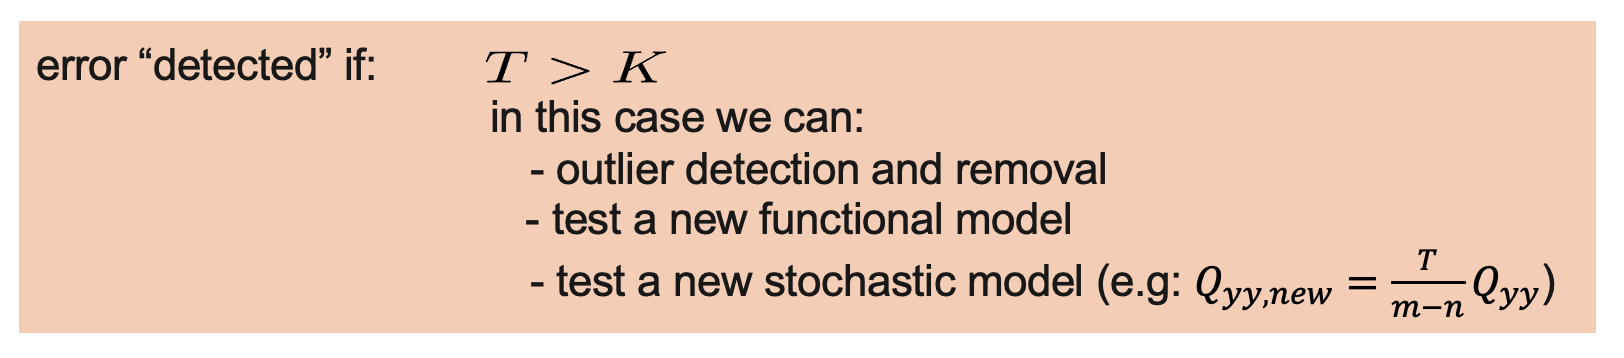

From the informatic point of view, you will need to know how to:

*   use the matrix multiplication operator (`@`): https://www.geeksforgeeks.org/numpy/multiplication-two-matrices-single-line-using-numpy-python/;
*   stack a sequence of input arrays vertically to make a single array using the function `numpy.vstack()`: https://www.geeksforgeeks.org/numpy-vstack-in-python/;
*   compute the rank of a matrix (function `numpy.linalg.matrix_rank`: https://codesignal.com/learn/courses/fundamentals-of-vectors-and-matrices-with-numpy/lessons/matrix-rank-with-numpy);
*   invert a matrix using the function `np.linalg.inv()`: https://www.geeksforgeeks.org/how-to-inverse-a-matrix-using-numpy/;
*   transpose a matrix using the method `.T` of numpy arrays: https://www.geeksforgeeks.org/transpose-matrix-single-line-python/;
*   create a diagonal matrix from a NumPy array: https://sparkbyexamples.com/python/how-to-get-numpy-diagonal/#:~:text=Numpy%20diag()%20function%20is,1%20for%20the%20below%20diagonal (see Section 5 of the link);
*   use the normal percentiles for computing the scaling factor for the confidence intervals at the desired probability (function `scipy.ppf`): https://pieriantraining.com/working-with-scipy-stats-norm-a-guide/#:~:text=Finding%20Percentiles%20with%20Scipy%20Stats%20Norm;
* use the `numpy.max()` function to find the maximum value in a NumPy array: https://www.geeksforgeeks.org/python/find-the-maximum-and-minimum-element-in-a-numpy-array/;
* use the `numpy.where()` function to find the indices of elements in an array that meet a specific condition:  https://www.geeksforgeeks.org/numpy-where-in-python/;
*   use the $\chi^2$ pdf for computing the test statistic $K$: https://www.geeksforgeeks.org/scipy-stats-chi2-python/
*  delete an element from a numpy array using the method `np.delete()`: https://www.geeksforgeeks.org/;how-to-remove-specific-elements-from-a-numpy-array/;
*  to understand how to implent logical conditions and conditional statements (`if`, `else`) in Python: https://www.w3schools.com/python/python_conditions.asp.

# Linear trend model

$E\{\underline{y}\} = x_0 + x_1 \cdot t$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from numpy.linalg import inv

# 1 - Import the data (sea level measurements (in cm))
# If you are running this notebook on your own computer,
# make sure that W6_syntheticdata4.txt is downloaded and placed in a folder
# called "sample_data" in the same directory as this notebook
# Alternatively, you can change the file path below
y= np.genfromtxt('sample_data/W6_syntheticdata4.txt')

# Compute the number of observations and store it in the variable named m
m = 0 # replace the 0 with the correct expression

# Define the vector of times (in years)
t = np.linspace(1,m,m)

'''
# Remove the outlier
# Uncomment the following lines to remove the outlier
index_outlier = 0 # replace the 0 with the correct expression
y = np.delete(y,index_outlier)
t = np.delete(t,index_outlier)
m = len (y)
'''

print("Number of observations: ", m)
print('y\n',y)
print('t\n',t)

# Define the standard deviation of the measurments (in cm) and store it in the variable named sigmay
sigmay = 0  #[cm]
print('σy [cm]\n', sigmay)

# Define the covariance matrix of observations and store it in the variable named Qyy
Qyy = 0 # replace the 0 with the correct expression
print('Qyy\n', Qyy)
#print('Qyy shape\n', Qyy.shape)

# Define the design matrix for the linear model and store it in the variable named A
A = 0 # replace the 0 with the correct expression
print('A\n', A)
#print('A shape\n', A.shape)

# Compute the rank of the design matrix and store it in a variable named rankA
rankA = 0 # replace the 0 with the correct expression
print('Rank of A\n', rankA)

# Define the number of unknows and store it in the variable named n
n = 0# replace the 0 with the correct expression
print("Number of unknowns (n): ", n)

# Compute the BLUE solution: xhat, yhat, and ehat
xhat= 0   # replace the 0 with the correct expression
yhat= 0   # replace the 0 with the correct expression
ehat= 0   # replace the 0 with the correct expression
print('xhat\n', xhat)
#print('xhat shape\n', xhat.shape)
print('yhat\n', yhat)
#print('yhat shape\n', yhat.shape)
print('ehat\n', ehat)
#print('ehat shape\n', ehat.shape)

# Compute the covariance matrices of xhat, yhat and ehat and store them in the variables named Qxhat and Qyhat
Qxhat= 0 # replace the 0 with the correct expression
Qyhat= 0 # replace the 0 with the correct expression
Qehat= 0 # replace the 0 with the correct expression
print('Qxhat\n', Qxhat)
#print('Qxhat shape\n', Qxhat.shape)
print('Qyhat\n', Qyhat)
#print('Qyhat shape\n', Qyhat.shape)
print('Qehat\n', Qehat)
#print('Qehat shape\n', Qehat.shape)


# Compute the scaling factor for confidence interval
# (for example for 95% interval, the scaling factor should be 1.96)
conf_level= 0   # replace the 0 with the correct expression
cint_scale=norm.ppf(1-(1-conf_level)/2)
print("Scale factor for the confidence interval at ",  conf_level*100, "% probability: ", format(cint_scale,'0.2f'))


# Compute the lower/upper bound of confidence intervals
yhat_L= 0 # replace the 0 with the correct expression
yhat_U= 0 # replace the 0 with the correct expression

# Compute the weighted sum of squared residuals which will serve as the OMT test statistic T
# and store it in a variable named Tq
Tq = 0 # replace the 0 with the correct expression

# compute K using the chi square distribution for the desired alpha (significance level)
alpha = 0                # replace the 0 with the correct expression
degrees_of_freedom = 0 # replace the 0 with the correct expression
print("Degrees of freedom (redundance): ", degrees_of_freedom)
K = chi2.ppf(1-alpha, df=degrees_of_freedom)  # critical value (you can use chi2inv(1-alpha,m-n))

print("K for the significance level of ",  alpha*100, "% and ", format(degrees_of_freedom,'0.0f'), 'degrees of freedom:', format(K,'0.3f'))



print("T:", format(Tq,'0.3f'), "K:", format(K,'0.3f'))
if Tq<K:
  print("Test passed (T<K): model accepted")
else:
  print("Test not passed (T>K): model rejected")

# Identify the index for which you have the largest absolute normalized residual



# Plot the reults
# (plot the observations, the estimated Y trend (Yhat) and the confidence levels of the adjusted observations


Number of observations:  0
y
 [ 3.4608  5.6308  4.4962  9.7645  4.9611  8.7935  8.5578  4.9095  9.5994
  6.0969 43.579   8.7046 11.599  15.599   7.8286 32.845  30.583  28.685
 43.015  31.509 ]
t
 []
σy [cm]
 0
Qyy
 0
A
 0
Rank of A
 0
Number of unknowns (n):  0
xhat
 0
yhat
 0
ehat
 0
Qxhat
 0
Qyhat
 0
Qehat
 0
Scale factor for the confidence interval at  0 % probability:  0.00
Degrees of freedom (redundance):  0
K for the significance level of  0 % and  0 degrees of freedom: nan
T: 0.000 K: nan
Test not passed (T>K): model rejected


# **Quadratic trend model**

$E\{\underline{y}\} = x_0 + x_1 \cdot t + x_2 \cdot t^2$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from numpy.linalg import inv

# 1 - Import the data (sea level measurements (in cm))
# If you are running this notebook on your own computer,
# make sure that W6_syntheticdata4.txt is downloaded and placed in a folder
# called "sample_data" in the same directory as this notebook
# Alternatively, you can change the file path below
y= np.genfromtxt('sample_data/W6_syntheticdata4.txt')

# Compute the number of observations and store it in the variable named m
m = 0 # replace the 0 with the correct expression

# Define the vector of times (in years)
t = np.linspace(1,m,m)

'''
# Remove the outlier
# Uncomment the following lines to remove the outlier
index_outlier = 0 # replace the 0 with the correct expression
y = np.delete(y,index_outlier)
t = np.delete(t,index_outlier)
m = len (y)
'''

print("Number of observations: ", m)
print('y\n',y)
print('t\n',t)

# Define the standard deviation of the measurments (in cm) and store it in the variable named sigmay
sigmay = 0 #[cm] # replace the 0 with the correct expression
print('σy [cm]\n', sigmay)

# Define the covariance matrix of observations and store it in the variable named Qyy
Qyy = 0 # replace the 0 with the correct expression
print('Qyy\n', Qyy)
#print('Qyy shape\n', Qyy.shape)

# Define the design matrix for the quadrtic model and store it in the variable named A
A = 0 # replace the 0 with the correct expression
print('A\n', A)
#print('A shape\n', A.shape)

# Compute the rank of the design matrix and store it in a variable named rankA
rankA = 0 # replace the 0 with the correct expression
print('Rank of A\n', rankA)

# Define the number of unknows and store it in the variable named n
n = 0 # replace the 0 with the correct expression
print("Number of unknowns (n): ", n)

# Compute the BLUE solution: xhat, yhat, and ehat
xhat = 0  # replace the 0 with the correct expression
yhat = 0  # replace the 0 with the correct expression
ehat = 0  # replace the 0 with the correct expression
print('xhat\n', xhat)
#print('xhat shape\n', xhat.shape)
print('yhat\n', yhat)
#print('yhat shape\n', yhat.shape)
print('ehat\n', ehat)
#print('ehat shape\n', ehat.shape)

# Compute the covariance matrices of xhat, yhat and ehat and store them in the variables named Qxhat and Qyhat
Qxhat = 0 # replace the 0 with the correct expression
Qyhat = 0 # replace the 0 with the correct expression
Qehat = 0 # replace the 0 with the correct expression
print('Qxhat\n', Qxhat)
#print('Qxhat shape\n', Qxhat.shape)
print('Qyhat\n', Qyhat)
#print('Qyhat shape\n', Qyhat.shape)
print('Qehat\n', Qehat)
#print('Qehat shape\n', Qehat.shape)

#  Compute the scaling factor for confidence interval
# (for example for 95% interval, the scaling factor should be 1.96)
conf_level= 0  # replace the 0 with the correct expression
cint_scale=norm.ppf(1-(1-conf_level)/2)
print("Scale factor for the confidence interval at ",  conf_level*100, "% probability: ", format(cint_scale,'0.2f'))


# Compute the lower/upper bound of confidence intervals
yhat_L = 0 # replace the 0 with the correct expression
yhat_U = 0 # replace the 0 with the correct expression

# Compute the weighted sum of squared residuals which will serve as the OMT test statistic T
# and store it in a variable named Tq
Tq = 0 # replace the 0 with the correct expression
print('Weighted sum of squared residuals (T)\n', Tq)

# Compute K using the chi square distribution for the desired alpha (significance level)
alpha = 0              # replace the 0 with the correct expression
degrees_of_freedom = 0 # replace the 0 with the correct expression
print("Degrees of freedom (redundance): ", degrees_of_freedom)
K = chi2.ppf(1-alpha, df=degrees_of_freedom)  # critical value (you can use chi2inv(1-alpha,m-n))

print("K for the significance level of ",  alpha*100, "% and ", format(degrees_of_freedom,'0.0f'), 'degrees of freedom:', format(K,'0.3f'))

print("T:", format(Tq,'0.3f'), "K:", format(K,'0.3f'))
if Tq<K:
  print("Test passed (T<K): model accepted")
else:
  print("Test not passed (T>K): model rejected")

# Identify the index for which you have the largest absolute normalized residual


# Plot the reults
# (plot the observations, the estimated Y trend (Yhat) and the confidence levels of the adjusted observations


Number of observations:  0
y
 [ 3.4608  5.6308  4.4962  9.7645  4.9611  8.7935  8.5578  4.9095  9.5994
  6.0969 43.579   8.7046 11.599  15.599   7.8286 32.845  30.583  28.685
 43.015  31.509 ]
t
 []
σy [cm]
 0
Qyy
 0
A
 0
Rank of A
 0
Number of unknowns (n):  0
xhat
 0
yhat
 0
ehat
 0
Qxhat
 0
Qyhat
 0
Qehat
 0
Scale factor for the confidence interval at  0 % probability:  0.00
Weighted sum of squared residuals (T)
 0
Degrees of freedom (redundance):  0
K for the significance level of  0 % and  0 degrees of freedom: nan
T: 0.000 K: nan
Test not passed (T>K): model rejected


# **Quadratic model with updated stochastic model**

$E\{\underline{y}\} = x_0 + x_1 \cdot t + x_2 \cdot t^2$

 $s=\frac{\hat{\underline{e}}^T Q_{yy}^-1\hat{\underline{e}}}{m-n}=\frac{T}{m-n}\rightarrow Q_{yy,new}=\frac{T}{m-n}Q_{yy} $

In [3]:
# Compute the scale factor S for the covariance matrix of the observations
# and store it in the variable named S
S = 0 # replace the 0 with the correct expression
print('Weighted sum of squared residuals (T)\n', Tq)
print('Redundance\n',m-n)
print('Scale factor S for the covariance matrix of the observation\n',S)


Weighted sum of squared residuals (T)
 0
Redundance
 0
Scale factor S for the covariance matrix of the observation
 0


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from numpy.linalg import inv

print('y\n',y)
print('t\n',t)

print("Number of observations: ", m)
# Define the standard deviation of the measurments (in cm) and store it in the variable named sigmay
# Use the value assumed in Qyy^-1 to compute the scaling factor in the previous cell
sigmay = 0  # replace the 0 with the correct expression #[cm]
print('σy [cm]\n', sigmay)
# Define the covariance matrix of observations and store it in the variable named Qyy
Qyy = 0 # replace the 0 with the correct expression
print('Qyy\n', Qyy)
#print('Qyy shape\n', Qyy.shape)

# Update the covariance matrix of observations using the computed scaling factor S
Qyy = 0                        # replace the 0 with the correct expression
new_sigmay = 0                 # replace the 0 with the correct expression
print('S\n',S)
print('Updated Qyy\n', Qyy)
#print('Updated Qyy shape\n', Qyy.shape)
print('New σy [cm]:\n',new_sigmay)

# Define the design matrix for the quadrtic model and store it in the variable named A
A = 0 # replace the 0 with the correct expression
print('A\n', A)
#print('A shape\n', A.shape)

# Compute the rank of the design matrix and store it in a variable named rankA
rankA = 0 # replace the 0 with the correct expression
print('Rank of A\n', rankA)

# Define the number of unknows and store it in the variable named n
n = 0 # replace the 0 with the correct expression
print("Number of unknowns (n): ", n)

# Compute the BLUE solution: xhat, yhat, and ehat
xhat= 0    # replace the 0 with the correct expression
yhat= 0    # replace the 0 with the correct expression
ehat= 0    # replace the 0 with the correct expression
print('xhat\n', xhat)
#print('xhat shape\n', xhat.shape)
print('yhat\n', yhat)
#print('yhat shape\n', yhat.shape)
print('ehat\n', ehat)
#print('ehat shape\n', ehat.shape)

# Compute the covariance matrices of xhat, yhat and ehat and store them in the variables named Qxhat and Qyhat
Qxhat = 0 # replace the 0 with the correct expression
Qyhat = 0 # replace the 0 with the correct expression
Qehat = 0 # replace the 0 with the correct expression
print('Qxhat\n', Qxhat)
#print('Qxhat shape\n', Qxhat.shape)
print('Qyhat\n', Qyhat)
#print('Qyhat shape\n', Qyhat.shape)
print('Qehat\n', Qehat)
#print('Qehat shape\n', Qehat.shape)

#  Compute the scaling factor for confidence interval
# (for example for 95% interval, the scaling factor should be 1.96)
conf_level= 0   # replace the 0 with the correct expression
cint_scale=norm.ppf(1-(1-conf_level)/2)
print("Scale factor for the confidence interval at ",  conf_level*100, "% probability: ", format(cint_scale,'0.2f'))

# Compute the lower/upper bound of confidence intervals
yhat_L= 0 # replace the 0 with the correct expression
yhat_U= 0 # replace the 0 with the correct expression

# Compute the new weighted sum of squared residuals which will serve as the OMT test statistic T
# and store it in a variable named Tq
Tq = 0 # replace the 0 with the correct expression

# compute K using the chi square distribution for the desired alpha (significance level)
alpha = 0                # replace the 0 with the correct expression
degrees_of_freedom = 0 # replace the 0 with the correct expression
print("Degrees of freedom (redundance): ", degrees_of_freedom)
K = chi2.ppf(1-alpha, df=degrees_of_freedom)  # critical value (you can use chi2inv(1-alpha,m-n))

print("K for the significance level of ",  alpha*100, "% and ", format(degrees_of_freedom,'0.0f'), 'degrees of freedom:', format(K,'0.3f'))

print("T:", format(Tq,'0.3f'), "K:", format(K,'0.3f'))
if Tq<K:
  print("Test passed (T<K): model accepted")
else:
  print("Test not passed (T>K): model rejected")


# Identify the index for which you have the maxium residual


# Plot the reults
# (plot the observations, the estimated Y trend (Yhat) and the confidence levels of the adjusted observations



y
 [ 3.4608  5.6308  4.4962  9.7645  4.9611  8.7935  8.5578  4.9095  9.5994
  6.0969 43.579   8.7046 11.599  15.599   7.8286 32.845  30.583  28.685
 43.015  31.509 ]
t
 []
Number of observations:  0
σy [cm]
 0
Qyy
 0
S
 0
Updated Qyy
 0
New σy [cm]:
 0
A
 0
Rank of A
 0
Number of unknowns (n):  0
xhat
 0
yhat
 0
ehat
 0
Qxhat
 0
Qyhat
 0
Qehat
 0
Scale factor for the confidence interval at  0 % probability:  0.00
Degrees of freedom (redundance):  0
K for the significance level of  0 % and  0 degrees of freedom: nan
T: 0.000 K: nan
Test not passed (T>K): model rejected


**Q2:** For which model configuration(s) is the OMT not rejected?

What factors contributed to the OMT not being rejected? Discuss the effects of outlier removal, the choice of functional model, and the rescaling of the stochastic model, where applicable.

***Edit the cell to reply***

**Q3:** The initially assumed standard deviation of the observations (σ = 2 cm) may be too optimistic.

Based on the results of the adjustment, what would be a more appropriate value for the standard deviation $\sigma_y$ of the observations?

Explain your reasoning and indicate how you obtained your proposed value.

***Edit the cell to reply***

***Q4***: For both functional models (linear and quadratic), report the following information, considering the cases before and after outlier removal, where applicable:
* number of observations (before and after the removal of the outlier);
* number of unknown parameters;
* dimensions (number of rows and number of columns) of the design matrix $A$ (before and after the removal of the outlier);
* dimensions (number of rows and number of columns) of the covariance matrix of the observations $Q_{yy}$ (before and after the removal of the outlier);
* dimensions (number of rows and number of columns) of the normal matrix $N$;
* dimensions (number of rows and number of columns) of the covariance matrix $Q_{\hat{x}\hat{x}}$ of the estimate $\hat{x}$;
* dimensions (number of rows and number of columns) of the covariance matrix $Q_{\hat{y}\hat{y}}$ of the adjusted observations $\hat{y}$ (before and after the removal of the outlier).
*  dimensions (number of rows and number of columns) of the covariance matrix $Q_{\hat{e}\hat{e}}$ of the residuals $\hat{e}$ (before and after the removal of the outlier).

***Edit the cell to reply***